# Decisão de implantação: validação cruzada aninhada, repetições em larga escala e custo de recursos

## Ficha do experimento

| Campo | Conteúdo |
|---|---|
| **Objetivo** | Comparar os melhores candidatos e, diante de desempenho preditivo semelhante, selecionar o de menor custo de implantação. |
| **Candidatos** | Random Forest (RF), MLP (`MLPClassifier`) e regressão logística com splines (LR splines). Referência: a regressão logística do baseline do usuário |
| **Hipótese H1** | os candidatos são **praticamente equivalentes** em ranking (AUC ≈ 0,86; diferenças dentro de ±0,005 de AP), como indicaram EXP-02, EXP-03 e EXP-04 |
| **Hipótese H2** | com tantas comparações, a CV **simples** superestima o desempenho dos candidatos mais flexíveis (MLP, RF); a CV **aninhada** mede esse otimismo |
| **Hipótese H3** | se H1 se confirmar, a decisão é definida pelo **custo de implantação** e pela calibração, não pelo ranking |
| **Regra de decisão** | fixada **antes** de rodar (seção 8) |
| **Dados** | IBM Telco Customer Churn: 7.043 clientes, 26,5 % de churn (mesma divisão 80/20 dos notebooks anteriores) |

## O que este notebook faz

| Etapa | O que mede | Por que importa |
|---|---|---|
| **A. Repetições em larga escala** | CV repetida (até 30 × 5 folds) dos modelos com **configuração fixa** | reduz o ruído da comparação; é barata |
| **B. CV aninhada** | para cada fold externo, **a busca de hiperparâmetros inteira** roda só com o treino do fold; o fold externo mede o resultado | mede o desempenho **do procedimento "buscar + treinar"** sem otimismo de seleção |
| **C. Busca final em larga escala** | busca aleatória grande no treino completo; paisagem de hiperparâmetros | mostra quão plana é a região de bons modelos |
| **D. Perfil de recursos** | tempo, CPU-segundos, núcleos efetivos, pico de RAM, latência, tamanho, escala | custos reais de treino e de inferência, na **sua** máquina |
| **E. Decisão** | regra pré-registrada: empate prático em ranking → vence o menor custo | recomendação auditável |
| **F. Confirmação no teste** | uso único do teste, **depois** da decisão | sanidade final |

## Antes de rodar

1. **Requisitos:** `scikit-learn >= 1.4`, `psutil` (`pip install psutil`), `cloudpickle` (`pip install cloudpickle`, normalmente já vem com o `joblib`), `joblib`, `threadpoolctl`, `scipy`, `pandas`, `seaborn`.
2. **Perfil de esforço:** edite `PROFILE` (seção 1) ou defina a variável de ambiente `EXP09_PROFILE`. `SMOKE` roda em minutos e só serve para verificar se tudo funciona; `STANDARD` é o intermediário; `STRESS` é o "máximo". **A seção 3 projeta o tempo de cada perfil com medições feitas na sua máquina; leia a projeção antes de iniciar a etapa B.**
3. **É retomável:** cada fold externo é gravado em disco (`exp09_resultados_<perfil>/`). Se o kernel cair ou você interromper, rode as células novamente: os folds já concluídos são pulados.
4. **Orçamento de tempo:** `TIME_BUDGET_HOURS` interrompe com segurança (depois de concluir o lote atual) e a análise usa os folds completos até ali.
5. **Em notebook de laptop:** conectado à energia, plano de energia em "Alto desempenho", outros programas pesados fechados. Temperatura alta reduz a frequência do processador e alonga o tempo.
6. **GPU:** o `scikit-learn` usa **apenas CPU**. A GTX 1650 não é usada por nenhum dos candidatos (ver seção 2).

## 1. Setup, configuração e perfis de esforço

In [ ]:
import ast
import gc
import json
import os
import platform
import subprocess
import tempfile
import threading
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from IPython.display import display
from joblib import Parallel, delayed
from scipy import stats
from scipy.stats import loguniform, randint
from threadpoolctl import threadpool_limits

try:
    import cloudpickle                              # joblib recente: pacote próprio (dependência do joblib)
except ImportError:
    from joblib.externals import cloudpickle        # joblib antigo: versão embutida

try:
    import psutil
except ImportError as exc:
    raise ImportError("Este notebook mede memória e CPU com o psutil. Instale com:  pip install psutil") from exc

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import (
    ParameterSampler, RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, train_test_split,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder, QuantileTransformer, SplineTransformer, StandardScaler,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

SK_VERSION = tuple(int(x) for x in sklearn.__version__.split(".")[:2])
assert SK_VERSION >= (1, 4), f"scikit-learn >= 1.4 é necessário (RF com NaN nativo); encontrado {sklearn.__version__}"

# ----------------------------- PERFIL DE ESFORÇO -----------------------------
PROFILE = os.environ.get("EXP09_PROFILE", "STRESS")      # "SMOKE" | "STANDARD" | "STRESS"
PROFILES = {
    # outer_*: CV externa da etapa B | inner_*/n_iter: busca interna | stageA_repeats: repetições da etapa A
    # final_*: busca final (etapa C) | prof_repeats: repetições das medições de recursos | scale_factors: ×linhas no teste de escala
    "SMOKE":    dict(outer_splits=3, outer_repeats=1,  inner_splits=2, n_iter=3,  stageA_repeats=2,  final_iter=4,   final_inner=3, prof_repeats=2,  scale_factors=(1, 2),    n_single=40),
    "STANDARD": dict(outer_splits=5, outer_repeats=3,  inner_splits=3, n_iter=20, stageA_repeats=10, final_iter=40,  final_inner=5, prof_repeats=5,  scale_factors=(1, 4),    n_single=200),
    "STRESS":   dict(outer_splits=5, outer_repeats=10, inner_splits=5, n_iter=40, stageA_repeats=30, final_iter=150, final_inner=5, prof_repeats=10, scale_factors=(1, 5, 10), n_single=300),
}
P = PROFILES[PROFILE]

# ------------------------------- RECURSOS ------------------------------------
PHYSICAL_CORES = psutil.cpu_count(logical=False) or max(1, (os.cpu_count() or 2) // 2)
LOGICAL_CORES = psutil.cpu_count(logical=True) or (os.cpu_count() or 1)
N_JOBS = PHYSICAL_CORES            # trabalhadores paralelos; cada um usa 1 thread (evita saturar o processador)
TRAIN_THREADS = LOGICAL_CORES      # threads usadas na medição "com todos os recursos" (seção 6)
TIME_BUDGET_HOURS = None           # ex.: 6.0 para parar com segurança depois de 6 h (None = sem limite)
MIN_FREE_RAM_GB = 1.5              # abaixo disso, o lote seguinte roda com metade dos trabalhadores
PARALLEL_EFFICIENCY = 0.80         # fator usado só na projeção de tempo

# ------------------------------- SEMENTES E REGRAS ---------------------------
SEED = 42            # divisão treino/teste e modelos (a mesma dos notebooks anteriores)
OUTER_SEED = 2025    # folds externos da CV aninhada (independentes das sementes 42, 2024 e 777 usadas antes)
STAGEA_SEED = 2026   # folds da etapa A
TEST_SIZE = 0.20
TARGET = "Churn Value"
RECALL_FLOOR = 0.80
N_BOOT = 1000

# Regra de decisão (pré-registrada; ver seção 8)
ROPE_AP, ROPE_AUC = 0.005, 0.003           # diferença abaixo da qual dois modelos são "praticamente equivalentes"
TIE_MAX_PROB_WORSE = 0.20                  # empata com o melhor se P(ser pior que o melhor por mais que o ROPE) < 20 %
COST_WEIGHTS = dict(train_cpu_s=0.20, train_ram_mb=0.15, latency_ms=0.25, model_mb=0.10, ece=0.15, interpretability=0.15)
INTERPRETABILITY = {"RF": 0.3, "MLP": 0.1, "LR splines": 1.0, "LR baseline": 1.0}   # 0-1, julgamento do analista; edite

OUT_DIR = Path(f"exp05_resultados_{PROFILE.lower()}")
for sub in ("nested", "stageA"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)
P80 = f"P@R{int(RECALL_FLOOR * 100)}"
print(f"Perfil: {PROFILE} | trabalhadores: {N_JOBS} (núcleos físicos {PHYSICAL_CORES}, lógicos {LOGICAL_CORES}) | saída: {OUT_DIR}/")
print({k: v for k, v in P.items()})

Perfil: STRESS | trabalhadores: 4 (núcleos físicos 4, lógicos 8) | saída: exp05_resultados_stress/
{'outer_splits': 5, 'outer_repeats': 10, 'inner_splits': 5, 'n_iter': 40, 'stageA_repeats': 30, 'final_iter': 150, 'final_inner': 5, 'prof_repeats': 10, 'scale_factors': (1, 5, 10), 'n_single': 300}


## 2. Inventário do hardware e do software

O que o `scikit-learn` aproveita do seu equipamento: **núcleos de CPU** (RF e ExtraTrees via `n_jobs`; boosting via OpenMP; álgebra linear do MLP via BLAS) e **RAM**. **GPU: não**. O Iris Xe e a GTX 1650 ficam ociosos nestes modelos; frameworks de GPU só compensariam com dados e redes muito maiores.

In [2]:
def hardware_report():
    vm = psutil.virtual_memory()
    freq = psutil.cpu_freq()
    info = {
        "Sistema": f"{platform.system()} {platform.release()}",
        "Processador": platform.processor() or platform.machine(),
        "Núcleos físicos / lógicos": f"{PHYSICAL_CORES} / {LOGICAL_CORES}",
        "Frequência (MHz) atual / máxima": f"{freq.current:.0f} / {freq.max:.0f}" if freq else "n/d",
        "RAM total / disponível (GB)": f"{vm.total / 2**30:.1f} / {vm.available / 2**30:.1f}",
        "Python": platform.python_version(),
    }
    for lib in (np, pd, scipy, sklearn, joblib):
        info[lib.__name__] = lib.__version__
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=5)
        info["GPU (detectada, NÃO usada pelo scikit-learn)"] = out.stdout.strip() or "não detectada"
    except Exception:
        info["GPU"] = "nvidia-smi indisponível"
    return pd.Series(info, name="valor")

display(hardware_report().to_frame())

,valor
Sistema,Windows 11
Processador,"Intel64 Family 6 Model 140 Stepping 1, Genuine..."
Núcleos físicos / lógicos,4 / 8
Frequência (MHz) atual / máxima,3110 / 3110
RAM total / disponível (GB),7.8 / 0.8
Python,3.12.1
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
sklearn,1.9.1


## 3. Dados

Mesma preparação dos notebooks anteriores (EXP-07 e EXP-08): 19 variáveis (3 numéricas, 16 categóricas), `Total Charges` ausente preservado como NaN (cada modelo o trata à sua maneira) e o baseline com as 23 variáveis do `2-baseline.ipynb` (inclui geografia). **A CV aninhada e todas as buscas usam somente o treino; o teste só é aberto na etapa F.**

In [3]:
raw = pd.read_excel("../data/telco_customer_churn.xlsx")
df = raw.copy()
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"].astype("string").str.strip().replace("", pd.NA), errors="coerce").astype("float64")

DROP = ["CustomerID", "Count", "Country", "State", "Churn Label", "Churn Reason", "Churn Score", "CLTV"]
GEO = ["City", "Zip Code", "Lat Long", "Latitude", "Longitude"]
NUM = ["Tenure Months", "Monthly Charges", "Total Charges"]
FEATURES = [c for c in df.columns if c not in DROP + GEO + [TARGET]]
BASELINE_FEATURES = [c for c in df.columns if c not in DROP + ["Lat Long", TARGET]]
CAT = [c for c in FEATURES if c not in NUM]
NUM_BASE, CAT_BASE = NUM + ["Zip Code", "Latitude", "Longitude"], CAT + ["City"]

X = df[BASELINE_FEATURES].copy()
y = df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
y_train_arr, y_test_arr = y_train.to_numpy(), y_test.to_numpy()
print(f"{len(FEATURES)} variáveis ({len(NUM)} numéricas + {len(CAT)} categóricas) | treino {X_train.shape} | teste {X_test.shape} | churn {y.mean():.3f}")

19 variáveis (3 numéricas + 16 categóricas) | treino (5634, 23) | teste (1409, 23) | churn 0.265


## 4. Ferramentas: métricas, estatística da comparação e monitor de recursos

**Estatística.** Em CV repetida os folds compartilham dados de treino, então os resultados **não são independentes** e o teste t comum é otimista. Usa-se a correção de **Nadeau-Bengio**: variância multiplicada por `(1/k + n_teste/n_treino)`, com `k` folds e `n_teste/n_treino = 1/(K-1)` para K-fold. A mesma distribuição t corrigida dá a **probabilidade de equivalência prática** (ROPE): P(modelo pior), P(equivalente) e P(modelo melhor). Comparações múltiplas usam a correção de Holm.

**Recursos.** O `ResourceMonitor` amostra a memória residente do processo a cada 10 ms numa thread à parte (pico = máximo amostrado menos a memória antes da chamada) e mede CPU-segundos (usuário + sistema, somando todas as threads) e o tempo de relógio. Núcleos efetivos = CPU-segundos / tempo de relógio. Treinos muito curtos (< 50 ms) podem perder o pico de memória.

In [4]:
def precision_at_recall(y_true, proba, floor=RECALL_FLOOR):
    pr, rc, _ = precision_recall_curve(y_true, proba)
    return pr[np.where(rc[:-1] >= floor)[0][-1]]


def expected_calibration_error(y_true, proba, bins=10):
    q = pd.qcut(proba, bins, duplicates="drop")
    g = pd.DataFrame({"y": y_true, "p": proba, "q": q}).groupby("q", observed=True).agg(y=("y", "mean"), p=("p", "mean"), n=("y", "size"))
    return float((g["n"] * (g["y"] - g["p"]).abs()).sum() / g["n"].sum())


def score_all(y_true, proba):
    return {"AUC": roc_auc_score(y_true, proba), "AP": average_precision_score(y_true, proba),
            P80: precision_at_recall(y_true, proba), "Brier": brier_score_loss(y_true, proba),
            "ECE": expected_calibration_error(y_true, proba)}


def corrected_t(d, n_splits):
    """Média, erro-padrão corrigido (Nadeau-Bengio), t e p bicaudal para diferenças pareadas por fold."""
    d = np.asarray(d, float); k = len(d)
    if k < 3 or d.var(ddof=1) == 0:
        return d.mean(), np.nan, np.nan, np.nan
    se = np.sqrt((1.0 / k + 1.0 / (n_splits - 1)) * d.var(ddof=1))
    t = d.mean() / se
    return d.mean(), se, t, 2 * stats.t.sf(abs(t), k - 1)


def rope_probs(d, n_splits, rope):
    """(P[modelo A pior por mais que o ROPE], P[equivalente], P[A melhor por mais que o ROPE]) com posterior t corrigida."""
    d = np.asarray(d, float); k = len(d)
    se = np.sqrt((1.0 / k + 1.0 / (n_splits - 1)) * max(d.var(ddof=1), 1e-12))
    dist = stats.t(df=k - 1, loc=d.mean(), scale=se)
    return dist.cdf(-rope), dist.cdf(rope) - dist.cdf(-rope), dist.sf(rope)


def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i]); adj[i] = min(1.0, running)
    return adj


class ResourceMonitor:
    """Context manager: tempo de relógio, CPU-segundos (todas as threads) e pico de memória residente (RSS)."""
    def __init__(self, interval=0.01):
        self.interval = interval; self.proc = psutil.Process(); self._stop = threading.Event()

    def _sample(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, self.proc.memory_info().rss)
            time.sleep(self.interval)

    def __enter__(self):
        gc.collect()
        self.start_rss = self.peak = self.proc.memory_info().rss
        c = self.proc.cpu_times(); self.cpu0 = c.user + c.system
        self._thread = threading.Thread(target=self._sample, daemon=True); self._thread.start()
        self.t0 = time.perf_counter()
        return self

    def __exit__(self, *exc):
        self.wall = time.perf_counter() - self.t0
        self._stop.set(); self._thread.join()
        self.peak = max(self.peak, self.proc.memory_info().rss)
        c = self.proc.cpu_times(); self.cpu = c.user + c.system - self.cpu0

    def result(self):
        return {"wall_s": self.wall, "cpu_s": self.cpu, "cores_used": self.cpu / self.wall if self.wall > 0 else np.nan,
                "ram_peak_mb": (self.peak - self.start_rss) / 2**20, "rss_end_mb": self.proc.memory_info().rss / 2**20}


def clean_params(p):
    """Converte escalares numpy em Python para que str(params) seja lido por ast.literal_eval."""
    out = {}
    for k, v in p.items():
        out[k] = v.item() if isinstance(v, (np.floating, np.integer)) else v
    return out

## 5. Candidatos, espaços de busca e configurações fixas

| Candidato | Configuração fixa (etapa A) | Espaço de busca (etapas B e C) |
|---|---|---|
| **RF** | RF-A da EXP-07 (entropy, profundidade 8, folha 11, `max_features` 0,4, sem peso) | profundidade, folha, divisão, `max_features`, critério, subamostra por árvore, `ccp_alpha`, `class_weight` |
| **MLP** | MLP-A da EXP-08 (quantis, 1 camada de 32 neurônios, logística, L2 0,0442, 100 épocas) | pré-processamento, arquitetura, L2, taxa, lote, ativação, parada antecipada ou épocas fixas |
| **LR splines** | splines (6 nós), C = 0,1 | C, número de nós, grau |
| **LR baseline** | regressão logística balanceada do baseline do usuário, com geografia | sem busca (referência) |

In [5]:
def make_rf(n_jobs=1, n_estimators=300, **kw):
    pre = ColumnTransformer([("num", "passthrough", NUM), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    params = dict(criterion="entropy", max_depth=8, max_features=0.4, min_samples_leaf=11, min_samples_split=20, ccp_alpha=0.001)
    params.update(kw)
    return Pipeline([("pre", pre), ("clf", RandomForestClassifier(n_estimators=n_estimators, random_state=SEED, n_jobs=n_jobs, **params))])


def make_mlp_pipeline(prep="quantile", hidden=(32,), alpha=0.0442, lr=0.003, batch=128, act="logistic", early=False,
                      max_iter=100, seed=SEED, patience=10, tol=1e-4, n_knots=6):
    imp = SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)
    if prep == "spline":
        num_t = Pipeline([("imp", imp), ("spl", SplineTransformer(n_knots=n_knots, degree=3, include_bias=False)), ("sc", StandardScaler())])
    elif prep == "quantile":
        num_t = Pipeline([("imp", imp), ("q", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED))])
    else:
        num_t = Pipeline([("imp", imp), ("sc", StandardScaler())])
    pre = ColumnTransformer([("num", num_t, NUM), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    kw = dict(hidden_layer_sizes=hidden, alpha=alpha, activation=act, solver="adam", max_iter=max_iter, random_state=seed,
              learning_rate_init=lr, batch_size=batch, early_stopping=early, n_iter_no_change=patience, tol=tol)
    if early:
        kw["validation_fraction"] = 0.15
    return Pipeline([("pre", pre), ("clf", MLPClassifier(**kw))])


class MLPModel(ClassifierMixin, BaseEstimator):   # ClassifierMixin ANTES de BaseEstimator (exigido pelo scikit-learn recente)
    """Envoltório do MLP com hiperparâmetros no __init__ (permite a busca aleatória sobre o pré-processamento também).
    Padrões = MLP-A da EXP-08."""
    def __init__(self, prep="quantile", hidden=(32,), alpha=0.0442, lr=0.003, batch=128, act="logistic", early=False, epochs=100, seed=SEED):
        self.prep = prep; self.hidden = hidden; self.alpha = alpha; self.lr = lr; self.batch = batch
        self.act = act; self.early = early; self.epochs = epochs; self.seed = seed

    def fit(self, X, y):
        self.pipe_ = make_mlp_pipeline(prep=self.prep, hidden=self.hidden, alpha=self.alpha, lr=self.lr, batch=self.batch,
                                       act=self.act, early=self.early, max_iter=300 if self.early else self.epochs, seed=self.seed)
        self.pipe_.fit(X, y)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return self.pipe_.predict_proba(X)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def make_lr_spline(C=0.1, n_knots=6, degree=3):
    num_t = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0)),
                      ("spl", SplineTransformer(n_knots=n_knots, degree=degree, include_bias=False)), ("sc", StandardScaler())])
    pre = ColumnTransformer([("n", num_t, NUM), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=C, max_iter=5000))])


def make_baseline_lr():
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0)), ("sc", StandardScaler())]), NUM_BASE),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_BASE)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(class_weight="balanced", random_state=SEED, max_iter=2000))])


RF_SPACE = {
    "clf__max_depth": [None, 5, 6, 8, 10, 12, 16], "clf__min_samples_leaf": randint(3, 60), "clf__min_samples_split": randint(2, 50),
    "clf__max_features": ["sqrt", "log2", 0.15, 0.2, 0.3, 0.4, 0.5, 0.7], "clf__criterion": ["gini", "entropy", "log_loss"],
    "clf__max_samples": [None, 0.5, 0.7, 0.9], "clf__ccp_alpha": [0, 0, 0.0003, 0.0007, 0.001, 0.002],
    "clf__class_weight": [None, None, "balanced_subsample", {0: 1, 1: 2}, {0: 1, 1: 3}],
}
MLP_SPACE = {
    "prep": ["std", "spline", "quantile"], "hidden": [(16,), (32,), (64,), (128,), (32, 16), (64, 32), (64, 32, 16), (128, 64)],
    "alpha": loguniform(1e-4, 3.0), "lr": [3e-4, 1e-3, 3e-3, 1e-2], "batch": [32, 64, 128, 256],
    "act": ["relu", "tanh", "logistic"], "early": [True, True, False], "epochs": [30, 60, 100],
}

LR_SPACE = {"clf__C": loguniform(0.005, 5.0), "pre__n__spl__n_knots": [4, 5, 6, 8], "pre__n__spl__degree": [2, 3]}

CANDIDATES = {
    "RF": dict(make=lambda: make_rf(), space=RF_SPACE),
    "MLP": dict(make=lambda: MLPModel(), space=MLP_SPACE),
    "LR splines": dict(make=lambda: make_lr_spline(), space=LR_SPACE),
    "LR baseline": dict(make=make_baseline_lr, space=None),
}
SEARCHED = [n for n, s in CANDIDATES.items() if s["space"] is not None]
print("Candidatos:", list(CANDIDATES), "| com busca:", SEARCHED)

Candidatos: ['RF', 'MLP', 'LR splines', 'LR baseline'] | com busca: ['RF', 'MLP', 'LR splines']


## 6. Projeção de tempo na sua máquina (leia antes de iniciar a etapa B)

Mede o tempo real de ajuste de cada candidato **com 1 thread** (como nos trabalhadores paralelos), amostrando configurações aleatórias dos espaços de busca (as configurações variam muito em custo) sobre um treino do tamanho do de um fold externo. Daí projeta o tempo total de cada perfil.

In [6]:
def calibrate_fit_times(n_samples=4):
    Xa, ya = X_train.iloc[: int(len(X_train) * 0.8)], y_train.iloc[: int(len(X_train) * 0.8)]
    rows = []
    with threadpool_limits(limits=1):
        for name, spec in CANDIDATES.items():
            configs = list(ParameterSampler(spec["space"], n_samples, random_state=0)) if spec["space"] else [{}]
            ts = []
            for c in configs:
                m = clone(spec["make"]()).set_params(**c)
                t0 = time.perf_counter(); m.fit(Xa, ya); ts.append(time.perf_counter() - t0)
            rows.append({"candidato": name, "tempo médio de ajuste (s, 80 % do treino, 1 thread)": float(np.mean(ts)), "máx. amostrado (s)": float(np.max(ts))})
    return pd.DataFrame(rows).set_index("candidato")

fit_times = calibrate_fit_times()
display(fit_times.style.format("{:.2f}"))
T80 = fit_times.iloc[:, 0].to_dict()


def project_hours(profile_name):
    p = PROFILES[profile_name]; n_outer = p["outer_splits"] * p["outer_repeats"]; n_a = p["stageA_repeats"] * 5
    rows = []
    for name, spec in CANDIDATES.items():
        t = T80[name]
        nested = n_outer * t if spec["space"] is None else n_outer * (p["n_iter"] * p["inner_splits"] * t * (p["inner_splits"] - 1) / p["inner_splits"] + t)
        stage_a = n_a * t
        final = 0.0 if spec["space"] is None else p["final_iter"] * p["final_inner"] * t * (p["final_inner"] - 1) / p["final_inner"] + 6 * t
        rows.append({"candidato": name, "A (h)": stage_a, "B (h)": nested, "C (h)": final})
    d = pd.DataFrame(rows).set_index("candidato") / (N_JOBS * PARALLEL_EFFICIENCY) / 3600
    d.loc["TOTAL"] = d.sum()
    return d

for prof in PROFILES:
    d = project_hours(prof)
    print(f"\nPerfil {prof}: tempo projetado ≈ {d.loc['TOTAL'].sum():.1f} h  (A {d.loc['TOTAL', 'A (h)']:.2f} h | B {d.loc['TOTAL', 'B (h)']:.2f} h | C {d.loc['TOTAL', 'C (h)']:.2f} h)")
print(f"\nProjeção para o perfil escolhido ({PROFILE}), por candidato:")
display(project_hours(PROFILE).style.format("{:.2f}"))
print("Estimativa com eficiência paralela de {:.0%} e {} trabalhadores; o tempo real depende da temperatura e de outros programas.".format(PARALLEL_EFFICIENCY, N_JOBS))

,"tempo médio de ajuste (s, 80 % do treino, 1 thread)",máx. amostrado (s)
candidato,,
RF,1.67,2.63
MLP,0.65,0.96
LR splines,0.06,0.08
LR baseline,0.73,0.73



Perfil SMOKE: tempo projetado ≈ 0.0 h  (A 0.00 h | B 0.00 h | C 0.00 h)

Perfil STANDARD: tempo projetado ≈ 0.2 h  (A 0.01 h | B 0.13 h | C 0.03 h)

Perfil STRESS: tempo projetado ≈ 1.8 h  (A 0.04 h | B 1.67 h | C 0.13 h)

Projeção para o perfil escolhido (STRESS), por candidato:


,A (h),B (h),C (h)
candidato,,,
RF,0.02,1.17,0.09
MLP,0.01,0.45,0.03
LR splines,0.00,0.04,0.00
LR baseline,0.01,0.00,0.00
TOTAL,0.04,1.67,0.13


Estimativa com eficiência paralela de 80% e 4 trabalhadores; o tempo real depende da temperatura e de outros programas.


## 7. Etapa A: repetições em larga escala com configurações fixas

CV estratificada de 5 folds repetida `stageA_repeats` vezes (até 30 × 5 = 150 folds no perfil `STRESS`) para os candidatos com a **configuração fixa** dos experimentos anteriores. Não há busca aqui, então o custo é baixo; o objetivo é reduzir o ruído da comparação e ter uma primeira leitura das diferenças.

In [7]:
def stageA_task(fold, tr, te):
    out_file = OUT_DIR / "stageA" / f"fold_{fold:04d}.pkl"
    if out_file.exists():
        return fold
    rows = []
    with threadpool_limits(limits=1):
        Xa, ya, Xb, yb = X_train.iloc[tr], y_train.iloc[tr], X_train.iloc[te], y_train_arr[te]
        for name, spec in CANDIDATES.items():
            t0 = time.perf_counter(); m = spec["make"]().fit(Xa, ya); fit_s = time.perf_counter() - t0
            rows.append({"modelo": name, "fold": fold, "fit_s": fit_s, **score_all(yb, m.predict_proba(Xb)[:, 1])})
    joblib.dump(rows, out_file)
    return fold


cv_a = RepeatedStratifiedKFold(n_splits=5, n_repeats=P["stageA_repeats"], random_state=STAGEA_SEED)
folds_a = list(cv_a.split(X_train, y_train))
pending_a = [i for i in range(len(folds_a)) if not (OUT_DIR / "stageA" / f"fold_{i:04d}.pkl").exists()]
print(f"Etapa A: {len(folds_a)} folds, {len(pending_a)} pendentes, {N_JOBS} trabalhadores")
t0 = time.time()
if pending_a:
    Parallel(n_jobs=N_JOBS, verbose=5)(delayed(stageA_task)(i, *folds_a[i]) for i in pending_a)
print(f"Etapa A concluída em {(time.time() - t0) / 60:.1f} min")
stage_a = pd.DataFrame([r for i in range(len(folds_a)) for r in joblib.load(OUT_DIR / "stageA" / f"fold_{i:04d}.pkl")])

Etapa A: 150 folds, 150 pendentes, 4 trabalhadores


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   24.0s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:  1.7min
[Parallel(n_jobs=4)]: Done 150 out of 150 | elapsed:  3.8min finished


Etapa A concluída em 3.8 min


### 7.1 Funções de comparação (usadas também na etapa B)

In [8]:
def ci95_corrected(x, n_splits):
    x = np.asarray(x, float); k = len(x)
    if k < 3:
        return np.nan, np.nan
    half = stats.t.ppf(0.975, k - 1) * np.sqrt((1.0 / k + 1.0 / (n_splits - 1)) * x.var(ddof=1))
    return x.mean() - half, x.mean() + half


def compare_models(res, metric, n_splits, rope, models=None):
    """Tabelas de resumo e comparação par a par com t corrigido, Holm e probabilidades de equivalência prática."""
    models = models or sorted(res["modelo"].unique())
    piv = res.pivot(index="fold", columns="modelo", values=metric)[models].dropna()
    k = len(piv)
    cis = {c: ci95_corrected(piv[c], n_splits) for c in piv.columns}
    summ = pd.DataFrame({
        "média": piv.mean(), "desvio": piv.std(),
        "IC95 % (t corrigido)": [f"{cis[c][0]:.4f} a {cis[c][1]:.4f}" for c in piv.columns],
        "melhor em (% dos folds)": (piv.eq(piv.max(axis=1), axis=0)).mean() * 100, "posto médio": piv.rank(axis=1, ascending=False).mean()})
    rows = []
    for a, b in [(a, b) for i, a in enumerate(models) for b in models[i + 1:]]:
        d = piv[a] - piv[b]
        mean, se, t, p = corrected_t(d, n_splits)
        pw, pe, pb = rope_probs(d, n_splits, rope)
        rows.append({"A": a, "B": b, "Δ (A−B)": mean, "EP corrigido": se, "p": p, "P(A pior)": pw, "P(equivalentes)": pe, "P(A melhor)": pb})
    pair = pd.DataFrame(rows)
    if len(pair):
        pair["p (Holm)"] = holm(pair["p"].fillna(1.0).to_numpy())
    friedman = stats.friedmanchisquare(*[piv[m] for m in models]) if len(models) >= 3 and k >= 3 else None
    return piv, summ.sort_values("média", ascending=False), pair, friedman


def plot_comparison(piv, metric, title):
    order = piv.mean().sort_values(ascending=False).index
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    sns.boxplot(data=piv[order], ax=axes[0], color="#CFE0F0", fliersize=0)
    sns.stripplot(data=piv[order], ax=axes[0], color="#3C78A8", size=3, alpha=0.5)
    axes[0].set_ylabel(metric); axes[0].set_title(f"{title}: {metric} por fold", loc="left", weight="bold"); axes[0].tick_params(axis="x", rotation=20)
    delta = pd.DataFrame({a: {b: (piv[a] - piv[b]).mean() for b in order} for a in order})
    sns.heatmap(delta, annot=True, fmt="+.4f", cmap="RdBu", center=0, ax=axes[1], cbar=False)
    axes[1].set_title("Δ médio (coluna − linha)", loc="left", weight="bold")
    plt.tight_layout(); plt.show()


===== Etapa A · AP · 150 folds =====


,média,desvio,IC95 % (t corrigido),melhor em (% dos folds),posto médio
modelo,,,,,
MLP,0.6940,0.0253,0.6686 a 0.7193,59,1.51
LR splines,0.6896,0.0251,0.6645 a 0.7148,13,2.28
RF,0.6885,0.0252,0.6632 a 0.7137,27,2.25
LR baseline,0.6529,0.0245,0.6284 a 0.6774,1,3.96


A,B,Δ (A−B),EP corrigido,p,P(A pior),P(equivalentes),P(A melhor),p (Holm)
LR baseline,LR splines,-0.0368,0.0073,0.000,1.00,0.00,0.00,0.000
LR baseline,MLP,-0.0411,0.0069,0.000,1.00,0.00,0.00,0.000
LR baseline,RF,-0.0356,0.0080,0.000,1.00,0.00,0.00,0.000
LR splines,MLP,-0.0043,0.0023,0.064,0.39,0.61,0.00,0.191
LR splines,RF,+0.0012,0.0051,0.818,0.12,0.66,0.23,0.818
MLP,RF,+0.0055,0.0051,0.277,0.02,0.44,0.54,0.554


Friedman: χ² = 289.59, p = 1.779e-62


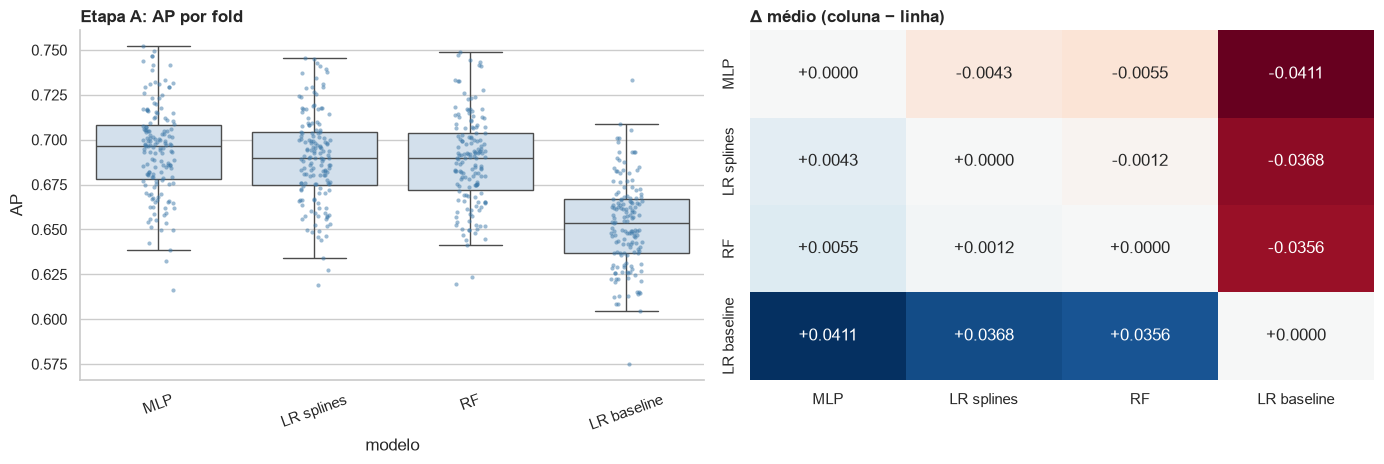


===== Etapa A · AUC · 150 folds =====


,média,desvio,IC95 % (t corrigido),melhor em (% dos folds),posto médio
modelo,,,,,
MLP,0.8642,0.0117,0.8525 a 0.8759,55,1.53
RF,0.8629,0.0113,0.8516 a 0.8742,35,2.01
LR splines,0.8620,0.0117,0.8503 a 0.8737,9,2.47
LR baseline,0.8482,0.0118,0.8364 a 0.8601,0,3.99


A,B,Δ (A−B),EP corrigido,p,P(A pior),P(equivalentes),P(A melhor),p (Holm)
LR baseline,LR splines,-0.0138,0.0022,0.000,1.00,0.00,0.00,0.000
LR baseline,MLP,-0.0160,0.0023,0.000,1.00,0.00,0.00,0.000
LR baseline,RF,-0.0147,0.0028,0.000,1.00,0.00,0.00,0.000
LR splines,MLP,-0.0022,0.0011,0.052,0.23,0.77,0.00,0.157
LR splines,RF,-0.0009,0.0019,0.645,0.13,0.85,0.02,0.972
MLP,RF,+0.0013,0.0019,0.486,0.01,0.81,0.18,0.972


Friedman: χ² = 306.81, p = 3.344e-66


,tempo de ajuste mediano (s),máximo (s)
modelo,,
LR baseline,1.45,3.01
LR splines,0.09,0.39
MLP,1.28,2.90
RF,2.63,4.05


In [9]:
for metric, rope in [("AP", ROPE_AP), ("AUC", ROPE_AUC)]:
    piv_a, summ_a, pair_a, fried_a = compare_models(stage_a, metric, 5, rope)
    print(f"\n===== Etapa A · {metric} · {len(piv_a)} folds =====")
    display(summ_a.style.format({"média": "{:.4f}", "desvio": "{:.4f}", "melhor em (% dos folds)": "{:.0f}", "posto médio": "{:.2f}"}))
    display(pair_a.style.format({"Δ (A−B)": "{:+.4f}", "EP corrigido": "{:.4f}", "p": "{:.3f}", "p (Holm)": "{:.3f}", "P(A pior)": "{:.2f}", "P(equivalentes)": "{:.2f}", "P(A melhor)": "{:.2f}"}).hide(axis="index"))
    if fried_a is not None:
        print(f"Friedman: χ² = {fried_a.statistic:.2f}, p = {fried_a.pvalue:.4g}")
    if metric == "AP":
        plot_comparison(piv_a, metric, "Etapa A")
display(stage_a.groupby("modelo")["fit_s"].agg(["median", "max"]).rename(columns={"median": "tempo de ajuste mediano (s)", "max": "máximo (s)"}).style.format("{:.2f}"))

## 8. Regra de decisão (pré-registrada)

1. **Critério principal:** AP médio da **CV aninhada** (etapa B), que já embute o custo de procurar hiperparâmetros.
2. **Empate prático:** um candidato empata com o melhor se a probabilidade de ele ser **pior que o melhor por mais que o ROPE** (`ROPE_AP` = 0,005) for **menor que `TIE_MAX_PROB_WORSE`** (20 %), usando a posterior t corrigida (Nadeau-Bengio).
3. **Desempate por custo:** entre os empatados, vence o de **menor custo de implantação**, a soma ponderada (pesos em `COST_WEIGHTS`) de cinco quantidades normalizadas em [0, 1] no conjunto empatado: CPU-segundos de treino, pico de RAM no treino, latência por linha (p95), tamanho do modelo e ECE, mais a interpretabilidade (invertida). Se houver um único candidato empatado, ele vence sem desempate.
4. **Teste:** só é aberto depois da decisão, para confirmação (etapa F).

A justificativa dos números do ROPE: 0,005 de AP equivale a cerca de metade do desvio entre folds e é menor que as diferenças que nos experimentos anteriores mudaram o ponto de operação. Edite `ROPE_AP`, `TIE_MAX_PROB_WORSE` e `COST_WEIGHTS` na seção 1 **antes** de rodar, se tiver critérios próprios.

## 9. Etapa B: validação cruzada aninhada

Em cada **fold externo**, e para **cada candidato**:

1. a **busca aleatória** (`n_iter` configurações × `inner_splits` folds internos, métrica AP) roda **somente** com o treino do fold externo;
2. a melhor configuração é reajustada nesse treino;
3. o fold externo, **que nunca foi visto pela busca**, mede AP, AUC, `P@R80`, Brier e ECE.

O resultado mede o desempenho do **procedimento completo** ("buscar + treinar"), sem o otimismo de escolher a melhor entre muitas configurações nos mesmos dados. Também registra o AP interno da melhor configuração; a diferença `AP interno − AP externo` é o **otimismo de seleção** de cada candidato. As previsões do fold externo ficam salvas para pooling e ensembles.

**Paralelismo:** um fold externo por trabalhador, 1 thread por trabalhador (`threadpool_limits(1)`). Os folds seguem a ordem repetição a repetição, então uma parada por orçamento de tempo deixa repetições completas.

In [10]:
def nested_task(fold, tr, te, p, search_seed):
    out_file = OUT_DIR / "nested" / f"fold_{fold:04d}.pkl"
    if out_file.exists():
        return fold
    rows, probas = [], {}
    with threadpool_limits(limits=1):
        Xa, ya, Xb, yb = X_train.iloc[tr], y_train.iloc[tr], X_train.iloc[te], y_train_arr[te]
        for name, spec in CANDIDATES.items():
            t0 = time.perf_counter()
            if spec["space"] is None:
                model = spec["make"]().fit(Xa, ya); params, inner_best, refit_s = None, np.nan, time.perf_counter() - t0
            else:
                rs = RandomizedSearchCV(spec["make"](), spec["space"], n_iter=p["n_iter"], scoring="average_precision",
                                        cv=StratifiedKFold(p["inner_splits"], shuffle=True, random_state=search_seed + fold),
                                        n_jobs=1, refit=True, random_state=search_seed + fold, error_score="raise")
                rs.fit(Xa, ya)
                model, params, inner_best, refit_s = rs.best_estimator_, str(clean_params(rs.best_params_)), float(rs.best_score_), float(getattr(rs, "refit_time_", np.nan))
            total_s = time.perf_counter() - t0
            proba = model.predict_proba(Xb)[:, 1]
            probas[name] = proba.astype(np.float32)
            rows.append({"modelo": name, "fold": fold, "params": params, "AP_interno": inner_best, "total_s": total_s, "refit_s": refit_s,
                         **score_all(yb, proba)})
    joblib.dump({"rows": rows, "te_idx": te, "probas": probas}, out_file)
    return fold


cv_b = RepeatedStratifiedKFold(n_splits=P["outer_splits"], n_repeats=P["outer_repeats"], random_state=OUTER_SEED)
folds_b = list(cv_b.split(X_train, y_train))


def run_nested(time_budget_hours=TIME_BUDGET_HOURS):
    pending = [i for i in range(len(folds_b)) if not (OUT_DIR / "nested" / f"fold_{i:04d}.pkl").exists()]
    print(f"Etapa B: {len(folds_b)} folds externos; {len(pending)} pendentes; {N_JOBS} trabalhadores; {P['n_iter']} configurações × {P['inner_splits']} folds internos por candidato")
    t_start, workers = time.time(), N_JOBS
    for s in range(0, len(pending), N_JOBS):
        chunk = pending[s:s + N_JOBS]
        if time_budget_hours is not None and (time.time() - t_start) / 3600 > time_budget_hours:
            print(f"Orçamento de {time_budget_hours} h atingido; parando com {len(pending) - s} folds pendentes."); break
        free_gb = psutil.virtual_memory().available / 2**30
        workers = max(1, N_JOBS // 2) if free_gb < MIN_FREE_RAM_GB else N_JOBS
        if workers < N_JOBS:
            print(f"Pouca RAM livre ({free_gb:.1f} GB): lote com {workers} trabalhadores.")
        Parallel(n_jobs=min(workers, len(chunk)))(delayed(nested_task)(i, *folds_b[i], P, OUTER_SEED) for i in chunk)
        done = len(folds_b) - len(pending) + s + len(chunk)
        el = (time.time() - t_start) / 60
        print(f"  {done}/{len(folds_b)} folds externos | {el:.1f} min decorridos | RAM livre {psutil.virtual_memory().available / 2**30:.1f} GB", flush=True)
    print(f"Etapa B: {(time.time() - t_start) / 60:.1f} min nesta execução")

run_nested()

Etapa B: 50 folds externos; 50 pendentes; 4 trabalhadores; 40 configurações × 5 folds internos por candidato
Pouca RAM livre (1.1 GB): lote com 2 trabalhadores.
  4/50 folds externos | 11.5 min decorridos | RAM livre 1.4 GB
Pouca RAM livre (1.4 GB): lote com 2 trabalhadores.
  8/50 folds externos | 23.0 min decorridos | RAM livre 1.4 GB
Pouca RAM livre (1.4 GB): lote com 2 trabalhadores.
  12/50 folds externos | 35.3 min decorridos | RAM livre 1.6 GB
  16/50 folds externos | 43.8 min decorridos | RAM livre 1.4 GB
Pouca RAM livre (1.4 GB): lote com 2 trabalhadores.
  20/50 folds externos | 55.9 min decorridos | RAM livre 1.1 GB
Pouca RAM livre (1.1 GB): lote com 2 trabalhadores.
  24/50 folds externos | 68.0 min decorridos | RAM livre 1.4 GB
Pouca RAM livre (1.4 GB): lote com 2 trabalhadores.
  28/50 folds externos | 80.7 min decorridos | RAM livre 1.3 GB
Pouca RAM livre (1.3 GB): lote com 2 trabalhadores.
  32/50 folds externos | 92.3 min decorridos | RAM livre 1.3 GB
Pouca RAM livre (

In [11]:
def load_nested():
    files = sorted((OUT_DIR / "nested").glob("fold_*.pkl"))
    rows, store = [], {}
    for f in files:
        d = joblib.load(f); rows += d["rows"]; store[int(f.stem.split("_")[1])] = d
    return pd.DataFrame(rows), store

nested, nested_store = load_nested()
n_done = nested["fold"].nunique()
print(f"Folds externos concluídos: {n_done} de {len(folds_b)}")

Folds externos concluídos: 50 de 50


### 9.1 Resultados da CV aninhada


===== CV aninhada · AP · 50 folds externos =====


,média,desvio,IC95 % (t corrigido),melhor em (% dos folds),posto médio
modelo,,,,,
MLP,0.6894,0.0207,0.6678 a 0.7110,48,1.74
LR splines,0.6876,0.0194,0.6674 a 0.7078,24,2.02
RF,0.6859,0.0187,0.6663 a 0.7054,28,2.30
LR baseline,0.6542,0.0224,0.6307 a 0.6776,0,3.94


A,B,Δ (A−B),EP corrigido,p,P(A pior),P(equivalentes),P(A melhor),p (Holm)
LR baseline,LR splines,-0.0334,0.0090,0.001,1.00,0.00,0.00,0.003
LR baseline,MLP,-0.0352,0.0086,0.000,1.00,0.00,0.00,0.001
LR baseline,RF,-0.0317,0.0094,0.001,1.00,0.00,0.00,0.006
LR splines,MLP,-0.0018,0.0027,0.508,0.12,0.87,0.01,1.000
LR splines,RF,+0.0018,0.0044,0.693,0.07,0.70,0.23,1.000
MLP,RF,+0.0036,0.0045,0.435,0.03,0.59,0.37,1.000


Friedman: χ² = 87.65, p = 7.009e-19

===== CV aninhada · AUC · 50 folds externos =====


,média,desvio,IC95 % (t corrigido),melhor em (% dos folds),posto médio
modelo,,,,,
MLP,0.8624,0.0105,0.8514 a 0.8734,48,1.76
RF,0.8623,0.0095,0.8523 a 0.8722,40,2.00
LR splines,0.8613,0.0099,0.8510 a 0.8717,12,2.28
LR baseline,0.8488,0.0112,0.8371 a 0.8604,0,3.96


A,B,Δ (A−B),EP corrigido,p,P(A pior),P(equivalentes),P(A melhor),p (Holm)
LR baseline,LR splines,-0.0126,0.0030,0.000,1.00,0.00,0.00,0.000
LR baseline,MLP,-0.0136,0.0027,0.000,1.00,0.00,0.00,0.000
LR baseline,RF,-0.0135,0.0035,0.000,1.00,0.00,0.00,0.001
LR splines,MLP,-0.0011,0.0013,0.421,0.07,0.92,0.00,1.000
LR splines,RF,-0.0009,0.0018,0.609,0.13,0.86,0.02,1.000
MLP,RF,+0.0001,0.0022,0.948,0.08,0.81,0.10,1.000


... (2 outputs left out)


===== CV aninhada · Brier · 50 folds externos =====


,média,desvio,IC95 % (t corrigido),melhor em (% dos folds),posto médio
modelo,,,,,
LR baseline,0.1577,0.0055,0.1519 a 0.1635,92,1.08
RF,0.1411,0.0125,0.1280 a 0.1542,8,2.20
MLP,0.1296,0.0050,0.1243 a 0.1348,0,3.24
LR splines,0.1288,0.0042,0.1244 a 0.1331,0,3.48



===== CV aninhada · ECE · 50 folds externos =====


,média,desvio,IC95 % (t corrigido),melhor em (% dos folds),posto médio
modelo,,,,,
LR baseline,0.1248,0.0088,0.1156 a 0.1341,70,1.30
RF,0.0804,0.0535,0.0246 a 0.1362,30,2.14
MLP,0.0311,0.0139,0.0166 a 0.0456,0,2.96
LR splines,0.0225,0.0060,0.0162 a 0.0288,0,3.60


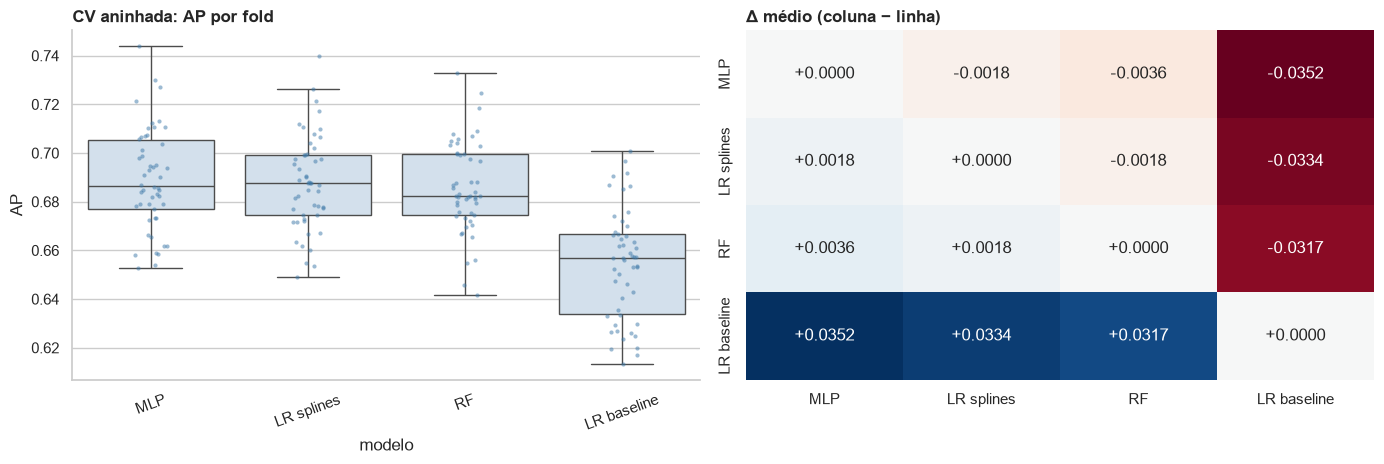

In [12]:
res_tables = {}
for metric, rope in [("AP", ROPE_AP), ("AUC", ROPE_AUC), (P80, ROPE_AP), ("Brier", 0.002), ("ECE", 0.005)]:
    piv_b, summ_b, pair_b, fried_b = compare_models(nested, metric, P["outer_splits"], rope)
    res_tables[metric] = (piv_b, summ_b, pair_b, fried_b)
    print(f"\n===== CV aninhada · {metric} · {len(piv_b)} folds externos =====")
    display(summ_b.style.format({"média": "{:.4f}", "desvio": "{:.4f}", "melhor em (% dos folds)": "{:.0f}", "posto médio": "{:.2f}"}))
    if metric in ("AP", "AUC"):
        display(pair_b.style.format({"Δ (A−B)": "{:+.4f}", "EP corrigido": "{:.4f}", "p": "{:.3f}", "p (Holm)": "{:.3f}", "P(A pior)": "{:.2f}", "P(equivalentes)": "{:.2f}", "P(A melhor)": "{:.2f}"}).hide(axis="index"))
        if fried_b is not None:
            print(f"Friedman: χ² = {fried_b.statistic:.2f}, p = {fried_b.pvalue:.4g}")
plot_comparison(res_tables["AP"][0], "AP", "CV aninhada")

### 9.2 Otimismo de seleção, custo da busca e estabilidade dos hiperparâmetros

- **Otimismo de seleção** = AP interno da melhor configuração − AP externo. Modelos mais flexíveis, com espaços de busca maiores, tendem a ter mais otimismo (H2).
- **Custo da busca** = tempo de relógio, em 1 thread, por fold externo (inclui busca e reajuste).
- **Estabilidade:** com que frequência cada valor de hiperparâmetro é escolhido ao longo dos folds. Se a escolha varia muito e o desempenho externo é parecido, a paisagem é **plana**: muitas configurações servem.

,AP interno,AP externo,otimismo médio,tempo de busca por fold (s),reajuste (s)
modelo,,,,,
LR splines,0.6905,0.6876,+0.0029,12,0.06
MLP,0.6928,0.6894,+0.0034,127,0.64
RF,0.6872,0.6859,+0.0013,221,1.53


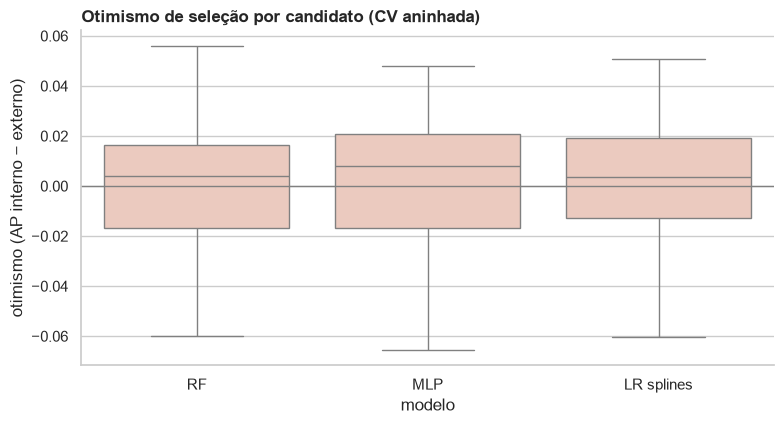


--- RF: hiperparâmetros escolhidos ao longo dos folds externos ---


hiperparâmetro,valores mais escolhidos (fração dos folds)
clf__ccp_alpha,0 (30%); 0.001 (26%); 0.0003 (18%); 0.0007 (16%); 0.002 (10%)
clf__class_weight,"None (44%); {0: 1, 1: 3} (24%); {0: 1, 1: 2} (18%); balanced_subsample (14%)"
clf__criterion,log_loss (48%); entropy (42%); gini (10%)
clf__max_depth,8 (42%); None (18%); 10 (16%); 12 (12%); 16 (12%)
clf__max_features,0.3 (36%); 0.4 (28%); 0.5 (16%); 0.2 (12%); 0.7 (8%)
clf__max_samples,0.7 (34%); 0.5 (26%); None (22%); 0.9 (18%)
clf__min_samples_leaf,contínuo: mediana 15 | P10-P90 7-26.2
clf__min_samples_split,contínuo: mediana 25 | P10-P90 5.9-43.1



--- MLP: hiperparâmetros escolhidos ao longo dos folds externos ---


hiperparâmetro,valores mais escolhidos (fração dos folds)
act,relu (44%); logistic (34%); tanh (22%)
alpha,contínuo: mediana 0.006854 | P10-P90 0.0004136-0.5171
batch,64 (46%); 32 (24%); 256 (20%); 128 (10%)
early,False (66%); True (34%)
epochs,30 (40%); 60 (34%); 100 (26%)
hidden,"(16,) (20%); (32, 16) (18%); (128,) (14%); (128, 64) (14%); (64, 32, 16) (12%); (32,) (8%)"
lr,0.0003 (32%); 0.003 (28%); 0.001 (26%); 0.01 (14%)
prep,quantile (100%)



--- LR splines: hiperparâmetros escolhidos ao longo dos folds externos ---


hiperparâmetro,valores mais escolhidos (fração dos folds)
clf__C,contínuo: mediana 0.3507 | P10-P90 0.0641-3.094
pre__n__spl__degree,3 (68%); 2 (32%)
pre__n__spl__n_knots,4 (46%); 8 (24%); 6 (18%); 5 (12%)


In [13]:
opt = nested[nested["params"].notna()].copy()
opt["otimismo (AP interno − externo)"] = opt["AP_interno"] - opt["AP"]
display(opt.groupby("modelo").agg(**{"AP interno": ("AP_interno", "mean"), "AP externo": ("AP", "mean"),
                                      "otimismo médio": ("otimismo (AP interno − externo)", "mean"),
                                      "tempo de busca por fold (s)": ("total_s", "median"), "reajuste (s)": ("refit_s", "median")})
        .style.format({"AP interno": "{:.4f}", "AP externo": "{:.4f}", "otimismo médio": "{:+.4f}", "tempo de busca por fold (s)": "{:.0f}", "reajuste (s)": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(8, 4.4))
sns.boxplot(data=opt, x="modelo", y="otimismo (AP interno − externo)", ax=ax, color="#F2C6B8")
ax.axhline(0, color="gray", lw=1); ax.set_title("Otimismo de seleção por candidato (CV aninhada)", loc="left", weight="bold")
plt.tight_layout(); plt.show()


def param_frequencies(model, top=6):
    ps = [ast.literal_eval(s) for s in nested.loc[nested["modelo"] == model, "params"].dropna()]
    rows = []
    for key in sorted({k for p in ps for k in p}):
        vals = pd.Series([str(p.get(key)) for p in ps])
        if vals.nunique() <= 12:
            vc = vals.value_counts(normalize=True).head(top)
            rows.append({"hiperparâmetro": key, "valores mais escolhidos (fração dos folds)": "; ".join(f"{k} ({v:.0%})" for k, v in vc.items())})
        else:
            num = pd.to_numeric(vals, errors="coerce").dropna()
            rows.append({"hiperparâmetro": key, "valores mais escolhidos (fração dos folds)": f"contínuo: mediana {num.median():.4g} | P10-P90 {num.quantile(.1):.4g}-{num.quantile(.9):.4g}" if len(num) else "n/d"})
    return pd.DataFrame(rows)

for m in SEARCHED:
    print(f"\n--- {m}: hiperparâmetros escolhidos ao longo dos folds externos ---")
    display(param_frequencies(m).style.hide(axis="index"))

### 9.3 Previsões agrupadas dos folds externos: calibração, ponto de operação e ensembles

Cada cliente do treino aparece em `outer_repeats` folds de teste externos; as previsões são agrupadas por repetição (cada repetição cobre todos os clientes uma vez) e as métricas de operação são calculadas por repetição e promediadas.

In [14]:
def pooled_by_repeat(name):
    out = []
    for r in range(P["outer_repeats"]):
        ids = [r * P["outer_splits"] + j for j in range(P["outer_splits"])]
        if not all(i in nested_store for i in ids):
            continue
        idx = np.concatenate([nested_store[i]["te_idx"] for i in ids]); p = np.concatenate([nested_store[i]["probas"][name] for i in ids]).astype(float)
        out.append((y_train_arr[idx], p))
    return out

rows = []
for name in CANDIDATES:
    reps = pooled_by_repeat(name)
    if reps:
        sc = [score_all(yy, pp) for yy, pp in reps]
        rows.append({"modelo": name, "repetições completas": len(reps), "AP (agrupado)": np.mean([s["AP"] for s in sc]), "AUC": np.mean([s["AUC"] for s in sc]),
                     P80: np.mean([s[P80] for s in sc]), "FP por 100 churners no recall 80 %": np.mean([100 * (1 - s[P80]) / s[P80] for s in sc]),
                     "Brier": np.mean([s["Brier"] for s in sc]), "ECE": np.mean([s["ECE"] for s in sc])})
pooled_tbl = pd.DataFrame(rows).set_index("modelo")
display(pooled_tbl.style.format({"AP (agrupado)": "{:.4f}", "AUC": "{:.4f}", P80: "{:.3f}", "FP por 100 churners no recall 80 %": "{:.0f}", "Brier": "{:.4f}", "ECE": "{:.4f}"}))

# Ensemble por média de postos, avaliado dentro de cada repetição completa
from scipy.stats import rankdata
ens_rows = []
reps_by_model = {m: pooled_by_repeat(m) for m in CANDIDATES}
n_rep = min(len(v) for v in reps_by_model.values())
for combo in [("RF", "MLP"), ("RF", "MLP"), ("RF", "MLP", "LR splines")]:
    sc = []
    for r in range(n_rep):
        yy = reps_by_model[combo[0]][r][0]
        p = np.mean([rankdata(reps_by_model[m][r][1]) / len(yy) for m in combo], axis=0)
        sc.append(score_all(yy, p))
    ens_rows.append({"ensemble": " + ".join(combo), "AP": np.mean([s["AP"] for s in sc]), "AUC": np.mean([s["AUC"] for s in sc]), P80: np.mean([s[P80] for s in sc])})
if ens_rows:
    print("\nEnsembles (média de postos) nas previsões externas agrupadas:")
    display(pd.DataFrame(ens_rows).set_index("ensemble").style.format({"AP": "{:.4f}", "AUC": "{:.4f}", P80: "{:.3f}"}))

,repetições completas,AP (agrupado),AUC,P@R80,FP por 100 churners no recall 80 %,Brier,ECE
modelo,,,,,,,
RF,10,0.6625,0.8531,0.534,87,0.1411,0.0693
MLP,10,0.6830,0.8604,0.546,83,0.1296,0.0140
LR splines,10,0.6854,0.8610,0.546,83,0.1288,0.0080
LR baseline,10,0.6523,0.8486,0.517,93,0.1577,0.1238



Ensembles (média de postos) nas previsões externas agrupadas:


,AP,AUC,P@R80
ensemble,,,
RF + MLP,0.6828,0.8618,0.546
RF + MLP,0.6828,0.8618,0.546
RF + MLP + LR splines,0.6871,0.8632,0.548


## 10. Etapa C: busca final em larga escala no treino completo

Busca aleatória grande (`final_iter` configurações × `final_inner` folds internos) em **todo o treino**, para cada candidato com espaço de busca. Produz (1) os modelos finais, (2) previsões out-of-fold (OOF) para uma análise exploratória dos pontos de operação e (3) a **paisagem de hiperparâmetros**: quantas configurações ficam a ≤ 0,002 e ≤ 0,005 de AP do melhor. Se uma fração grande das configurações está perto do melhor, a região é **plana** e buscar mais pode trazer ganhos limitados.

### Limitação das previsões OOF desta etapa

As previsões OOF são geradas **depois** que os hiperparâmetros foram escolhidos pela busca executada sobre todo o conjunto de treino. Assim, embora cada previsão seja produzida por um modelo que não treinou diretamente naquela observação, a própria observação já participou indiretamente da seleção dos hiperparâmetros. Por isso, essas previsões não constituem uma avaliação independente do procedimento completo de busca e tendem a ser otimistas.

Há uma segunda camada de seleção: os thresholds são escolhidos a partir dessas mesmas previsões OOF e depois avaliados no teste. Portanto, as métricas OOF e os thresholds servem como referência para definir pontos de operação, mas **não devem ser tratados como estimativas imparciais de generalização**. Para estimar o desempenho do processo completo de busca, a referência é a **CV aninhada da seção 9**, na qual a busca é refeita dentro de cada fold externo. O teste permanece como confirmação final, com a ressalva sobre o uso de `X_test` no perfil de inferência descrita na seção 16.

RF: 150 configurações × 5 folds em 5.6 min | melhor AP interno 0.6896
MLP: 150 configurações × 5 folds em 3.5 min | melhor AP interno 0.6931
LR splines: 150 configurações × 5 folds em 0.4 min | melhor AP interno 0.6902


,configurações,melhor AP,mediana,desvio entre configs,"% a ≤ 0,002 do melhor","% a ≤ 0,005 do melhor"
candidato,,,,,,
RF,150,0.6896,0.6805,0.0053,2,17
MLP,150,0.6931,0.6777,0.0735,5,11
LR splines,150,0.6902,0.6893,0.0020,74,89


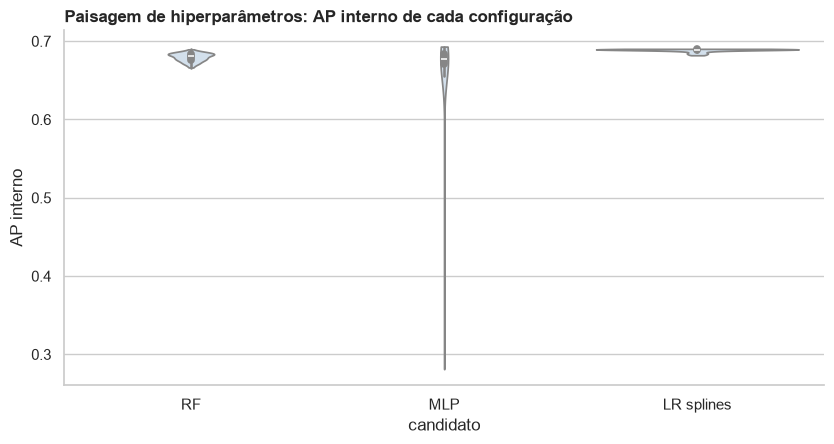

RF: melhores hiperparâmetros -> {'clf__ccp_alpha': 0.0003, 'clf__class_weight': {0: 1, 1: 3}, 'clf__criterion': 'entropy', 'clf__max_depth': 8, 'clf__max_features': 0.4, 'clf__max_samples': 0.5, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 22}
MLP: melhores hiperparâmetros -> {'act': 'logistic', 'alpha': 0.015275084713611421, 'batch': 64, 'early': False, 'epochs': 60, 'hidden': (64, 32), 'lr': 0.001, 'prep': 'quantile'}
LR splines: melhores hiperparâmetros -> {'clf__C': 0.3973573712326872, 'pre__n__spl__degree': 3, 'pre__n__spl__n_knots': 8}


In [15]:
FINAL_DIR = OUT_DIR / "final"
FINAL_DIR.mkdir(exist_ok=True)
cv_final = StratifiedKFold(P["final_inner"], shuffle=True, random_state=SEED)
final_search = {}
for name in SEARCHED:
    f = FINAL_DIR / f"busca_{name.replace(' ', '_')}.joblib"
    if f.exists():
        final_search[name] = joblib.load(f); print(f"{name}: busca carregada de {f.name}"); continue
    rs = RandomizedSearchCV(CANDIDATES[name]["make"](), CANDIDATES[name]["space"], n_iter=P["final_iter"],
                            scoring={"ap": "average_precision", "auc": "roc_auc"}, refit="ap", cv=cv_final,
                            n_jobs=N_JOBS, random_state=SEED, error_score="raise")
    t0 = time.perf_counter(); rs.fit(X_train, y_train); rs.wall_s_ = time.perf_counter() - t0
    joblib.dump(rs, f); final_search[name] = rs
    print(f"{name}: {P['final_iter']} configurações × {P['final_inner']} folds em {rs.wall_s_ / 60:.1f} min | melhor AP interno {rs.best_score_:.4f}")

final_models = {name: rs.best_estimator_ for name, rs in final_search.items()}
final_models["LR baseline"] = make_baseline_lr().fit(X_train, y_train)

rows = []
fig, ax = plt.subplots(figsize=(8.5, 4.6)); data = []
for name, rs in final_search.items():
    r = pd.DataFrame(rs.cv_results_); ap = r["mean_test_ap"]; best = ap.max()
    rows.append({"candidato": name, "configurações": len(r), "melhor AP": best, "mediana": ap.median(), "desvio entre configs": ap.std(),
                 "% a ≤ 0,002 do melhor": (ap >= best - 0.002).mean() * 100, "% a ≤ 0,005 do melhor": (ap >= best - 0.005).mean() * 100})
    data += [{"candidato": name, "AP interno": v} for v in ap]
land = pd.DataFrame(rows).set_index("candidato")
display(land.style.format({"melhor AP": "{:.4f}", "mediana": "{:.4f}", "desvio entre configs": "{:.4f}", "% a ≤ 0,002 do melhor": "{:.0f}", "% a ≤ 0,005 do melhor": "{:.0f}"}))
sns.violinplot(data=pd.DataFrame(data), x="candidato", y="AP interno", ax=ax, color="#CFE0F0", cut=0)
ax.set_title("Paisagem de hiperparâmetros: AP interno de cada configuração", loc="left", weight="bold")
plt.tight_layout(); plt.show()
for name, rs in final_search.items():
    print(f"{name}: melhores hiperparâmetros -> {clean_params(rs.best_params_)}")

In [16]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof = {name: cross_val_predict(clone(m), X_train, y_train, cv=cv5, method="predict_proba", n_jobs=N_JOBS)[:, 1] for name, m in final_models.items()}
oof_table = pd.DataFrame({n: score_all(y_train_arr, p) for n, p in oof.items()}).T
display(oof_table.style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}", "Brier": "{:.4f}", "ECE": "{:.4f}"}))
print("Atenção: o AP out-of-fold dos modelos que passaram por busca no mesmo treino é otimista; a medida honesta é a da CV aninhada (seção 9).")

,AUC,AP,P@R80,Brier,ECE
RF,0.8626,0.6850,0.539,0.1564,0.1398
MLP,0.8611,0.6862,0.548,0.1297,0.0192
LR splines,0.8613,0.6881,0.543,0.1286,0.0105
LR baseline,0.8482,0.6501,0.519,0.1579,0.1244


Atenção: o AP out-of-fold dos modelos que passaram por busca no mesmo treino é otimista; a medida honesta é a da CV aninhada (seção 9).


## 11. Etapa D: perfil de recursos (tempo, CPU, memória, latência, tamanho e escala)

Cada medição roda em um **processo novo e descartável** (`run_fresh`), sem paralelismo de trabalhadores, para atribuir recursos ao modelo e não ao notebook:

| Medida | Como |
|---|---|
| **Treino** | `fit` no treino completo, `prof_repeats` vezes, com **1 thread** (custo em CPU-segundos) e com **todas as threads lógicas** (melhor tempo de relógio) |
| **Núcleos efetivos** | CPU-segundos ÷ tempo de relógio |
| **Pico de RAM** | maior memória residente amostrada durante o `fit`, menos a de antes, **medida em processo novo** para cada treino (dentro de um mesmo processo o Python reaproveita memória já alocada e o pico "some") |
| **Inferência** | em processo novo: RAM do modelo carregado, latência de **1 linha** (p50/p95/p99, 1 thread, entrada como `DataFrame`, inclui o pré-processamento), vazão e RAM extra em lotes de 1.000 e 100.000 linhas |
| **Tamanho** | arquivo serializado (`cloudpickle`, sem compressão) |
| **Escala** | o treino é replicado ×k para medir como tempo e RAM crescem; o expoente `a` de `tempo ∝ linhas^a` permite projetar bases maiores (**extrapolação**; linhas replicadas servem para custo, não para precisão) |

**Como ler:** "RAM do modelo carregado" inclui ≈ 75 MB das **bibliotecas** que o processo importa ao carregar o modelo (comum a todos os candidatos); compare os candidatos **entre si**, não o valor absoluto. "RAM extra na predição" mostra o custo de pontuar um lote grande de uma vez; modelos com muitas colunas one-hot densas (como o baseline, com geografia) gastam muito mais.

In [17]:
from joblib.externals.loky import get_reusable_executor


def set_threads(est, n):
    est = clone(est)
    for k in est.get_params():
        if k == "n_jobs" or k.endswith("__n_jobs"):
            est.set_params(**{k: n})
    return est


def run_fresh(fn, *args):
    """Executa fn(*args) num processo NOVO e descartável. O Python reaproveita a memória já alocada dentro de um mesmo processo,
    então o pico de RAM de ajustes repetidos 'some'; um processo novo mede apenas o que aquela operação consome."""
    ex = get_reusable_executor(max_workers=1, kill_workers=True, reuse=False)
    try:
        return ex.submit(fn, *args).result()
    finally:
        ex.shutdown(wait=True)


def _train_worker(est, Xf, yf, threads):
    m = set_threads(est, threads)
    with threadpool_limits(limits=threads), ResourceMonitor() as mon:
        m.fit(Xf, yf)
    return mon.result()


def profile_training(est, Xf, yf, threads, repeats):
    return pd.DataFrame([run_fresh(_train_worker, est, Xf, yf, threads) for _ in range(repeats)])


def _infer_worker(path, X_pool, n_single, big):
    proc = psutil.Process(); base = proc.memory_info().rss
    model = cloudpickle.loads(Path(path).read_bytes()); gc.collect()
    out = {"ram_modelo_carregado_mb": (proc.memory_info().rss - base) / 2**20}
    rng = np.random.default_rng(0); lat = []
    with threadpool_limits(limits=1):
        model.predict_proba(X_pool.iloc[:5])                                  # aquecimento
        for i in rng.integers(0, len(X_pool), n_single):
            row = X_pool.iloc[[i]]; t0 = time.perf_counter(); model.predict_proba(row); lat.append((time.perf_counter() - t0) * 1000)
    out.update({"lat_p50_ms": np.percentile(lat, 50), "lat_p95_ms": np.percentile(lat, 95), "lat_p99_ms": np.percentile(lat, 99)})
    for n in big:
        Xb = X_pool.sample(n, replace=True, random_state=0)
        with ResourceMonitor() as mon:
            model.predict_proba(Xb)
        r = mon.result(); out[f"linhas_por_s_{n}"] = n / r["wall_s"]; out[f"RAM extra na predição de {n} linhas (MB)"] = r["ram_peak_mb"]
    return out


def profile_inference(model, n_single, big=(1000, 100000)):
    with tempfile.TemporaryDirectory() as d:
        path = Path(d) / "modelo.pkl"; path.write_bytes(cloudpickle.dumps(model))   # cloudpickle: embute classes definidas no notebook (ex.: MLPModel)
        size_mb = path.stat().st_size / 2**20
        out = run_fresh(_infer_worker, str(path), X_test, n_single, big)
    out["tamanho do modelo (MB)"] = size_mb
    return out


prof_rows, scale_rows = [], []
for name, fitted in final_models.items():
    est = clone(fitted)
    t1 = profile_training(est, X_train, y_train, 1, P["prof_repeats"])
    tn = profile_training(est, X_train, y_train, TRAIN_THREADS, P["prof_repeats"])
    infer = profile_inference(fitted, P["n_single"])
    prof_rows.append({"modelo": name,
                      "treino 1 thread: relógio (s)": t1["wall_s"].median(), "treino 1 thread: CPU-s": t1["cpu_s"].median(), "treino 1 thread: pico RAM extra (MB)": t1["ram_peak_mb"].median(),
                      f"treino {TRAIN_THREADS} threads: relógio (s)": tn["wall_s"].median(), f"treino {TRAIN_THREADS} threads: núcleos efetivos": tn["cores_used"].median(),
                      f"treino {TRAIN_THREADS} threads: pico RAM extra (MB)": tn["ram_peak_mb"].median(), **infer})
    for k in P["scale_factors"]:                                                  # escala: replica o treino ×k (1 thread, processo novo)
        Xk, yk = pd.concat([X_train] * k, ignore_index=True), pd.concat([y_train] * k, ignore_index=True)
        tk = profile_training(est, Xk, yk, 1, 1).iloc[0]
        scale_rows.append({"modelo": name, "k": k, "linhas": len(Xk), "relógio (s)": tk["wall_s"], "pico RAM extra (MB)": tk["ram_peak_mb"]})
    gc.collect()

prof = pd.DataFrame(prof_rows).set_index("modelo")
display(prof.T.style.format("{:.3g}"))

modelo,RF,MLP,LR splines,LR baseline
treino 1 thread: relógio (s),1.71,1.74,0.124,0.967
treino 1 thread: CPU-s,1.71,1.72,0.109,0.961
treino 1 thread: pico RAM extra (MB),8.82,3.81,4.85,94
treino 8 threads: relógio (s),3.42,1.73,3.05,4.13
treino 8 threads: núcleos efetivos,0.627,0.993,0.0602,1.45
treino 8 threads: pico RAM extra (MB),12.9,3.81,5.19,153
ram_modelo_carregado_mb,80.1,68.4,67.7,67.7
lat_p50_ms,18,5.55,4.88,6.11
lat_p95_ms,19.9,7.67,6.81,8.83
lat_p99_ms,21.3,8.32,7.31,9.58


,expoente do tempo (tempo ∝ linhas^a),"treino com 56,340 linhas (min, extrap.)","RAM de treino com 56,340 linhas (MB, extrap.)","treino com 563,400 linhas (min, extrap.)","RAM de treino com 563,400 linhas (MB, extrap.)"
modelo,,,,,
LR baseline,1.19,0.264,1.01e+03,4.09,1.03e+04
LR splines,0.853,0.0148,66.5,0.105,903
MLP,1.07,0.331,35.1,3.92,335
RF,0.878,0.21,40.9,1.58,187


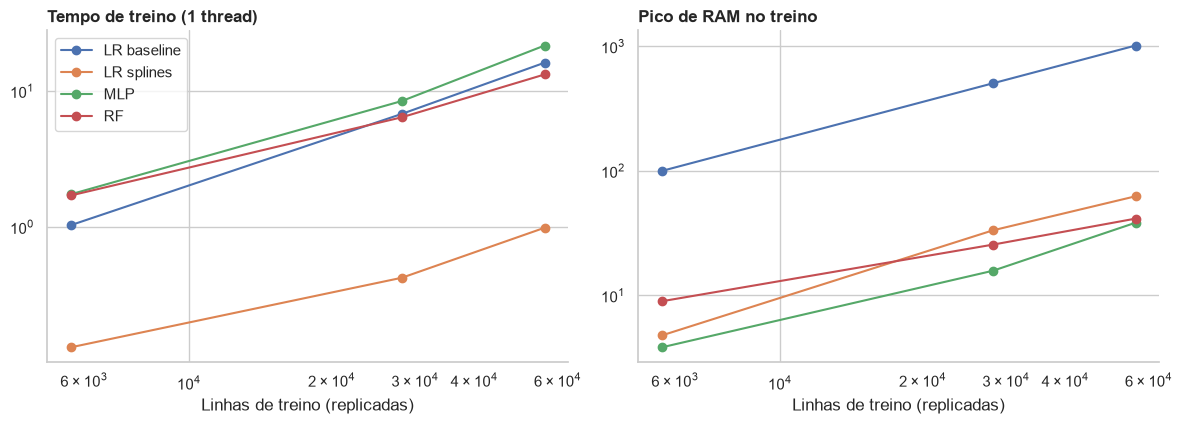

In [18]:
scale = pd.DataFrame(scale_rows)
proj_rows = []
for name, g in scale.groupby("modelo"):
    if len(g) >= 2:
        a, b = np.polyfit(np.log(g["linhas"]), np.log(np.maximum(g["relógio (s)"], 1e-3)), 1)
        am, bm = np.polyfit(np.log(g["linhas"]), np.log(np.maximum(g["pico RAM extra (MB)"], 1.0)), 1)
        row = {"modelo": name, "expoente do tempo (tempo ∝ linhas^a)": a}
        for mult in (10, 100):
            n = len(X_train) * mult
            row[f"treino com {n:,} linhas (min, extrap.)"] = np.exp(b) * n ** a / 60
            row[f"RAM de treino com {n:,} linhas (MB, extrap.)"] = np.exp(bm) * n ** am
        proj_rows.append(row)
if proj_rows:
    display(pd.DataFrame(proj_rows).set_index("modelo").style.format("{:.3g}"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for name, g in scale.groupby("modelo"):
    axes[0].plot(g["linhas"], g["relógio (s)"], marker="o", label=name); axes[1].plot(g["linhas"], g["pico RAM extra (MB)"], marker="o", label=name)
for ax, t in zip(axes, ["Tempo de treino (1 thread)", "Pico de RAM no treino"]):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Linhas de treino (replicadas)"); ax.set_title(t, loc="left", weight="bold")
axes[0].legend(); plt.tight_layout(); plt.show()

## 12. Etapa E: decisão

Aplica a regra da seção 8 aos resultados reais:
1. AP médio da CV aninhada define o **melhor** candidato;
2. os candidatos **empatados** com ele (probabilidade de serem piores por mais que o ROPE < `TIE_MAX_PROB_WORSE`) formam o conjunto elegível;
3. entre os elegíveis, vence o de **menor custo ponderado**.

A tabela de sensibilidade refaz a decisão com outros ROPE, outros limiares de empate e pesos iguais. Uma decisão que muda a cada variação não é robusta, e isso deve constar na conclusão.

In [19]:
def decide(rope=ROPE_AP, tie_prob=TIE_MAX_PROB_WORSE, weights=COST_WEIGHTS, verbose=False):
    piv, summ, _, _ = res_tables["AP"]
    best = summ.index[0]; tie_rows = [{"candidato": best, "AP médio": summ.loc[best, "média"], "P(pior que o melhor por > ROPE)": 0.0, "empata com o melhor": True}]
    for m in summ.index[1:]:
        d = piv[m] - piv[best]; pw, pe, pb = rope_probs(d, P["outer_splits"], rope)
        tie_rows.append({"candidato": m, "AP médio": summ.loc[m, "média"], "P(pior que o melhor por > ROPE)": pw, "empata com o melhor": pw < tie_prob})
    tie = pd.DataFrame(tie_rows).set_index("candidato")
    eligible = tie.index[tie["empata com o melhor"]].tolist()
    ece_mean = res_tables["ECE"][1]["média"]
    cost = pd.DataFrame({
        "train_cpu_s": prof.loc[eligible, "treino 1 thread: CPU-s"], "train_ram_mb": prof.loc[eligible, "treino 1 thread: pico RAM extra (MB)"],
        "latency_ms": prof.loc[eligible, "lat_p95_ms"], "model_mb": prof.loc[eligible, "tamanho do modelo (MB)"],
        "ece": ece_mean.loc[eligible], "interpretability": [1 - INTERPRETABILITY.get(m, 0.0) for m in eligible]}, index=eligible)
    norm = (cost - cost.min()) / (cost.max() - cost.min()).replace(0, 1)
    cost["custo ponderado"] = sum(weights[k] * norm[k] for k in weights)
    rec = cost["custo ponderado"].idxmin() if len(eligible) > 1 else eligible[0]
    if verbose:
        return rec, tie, cost
    return rec

rec, tie_tbl, cost_tbl = decide(verbose=True)
display(tie_tbl.style.format({"AP médio": "{:.4f}", "P(pior que o melhor por > ROPE)": "{:.2f}"}))
display(cost_tbl.sort_values("custo ponderado").style.format("{:.3g}"))
print(f"\n>>> Recomendação segundo a regra pré-registrada: {rec}")
if rec == "LR baseline":
    print("    (a regressão logística do baseline empatou com o melhor e é a mais barata: não há ganho demonstrado em trocá-la; ela, porém, está descalibrada)")

sens = []
for rope in (0.003, ROPE_AP, 0.010):
    for tp in (0.10, TIE_MAX_PROB_WORSE, 0.30):
        for wlabel, w in (("pesos padrão", COST_WEIGHTS), ("pesos iguais", {k: 1 / len(COST_WEIGHTS) for k in COST_WEIGHTS})):
            sens.append({"ROPE (AP)": rope, "P(pior) máx.": tp, "pesos": wlabel, "recomendação": decide(rope, tp, w)})
sens = pd.DataFrame(sens)
display(sens.pivot_table(index=["ROPE (AP)", "P(pior) máx."], columns="pesos", values="recomendação", aggfunc="first"))
print("Recomendações distintas na análise de sensibilidade:", sens["recomendação"].value_counts().to_dict())

,AP médio,P(pior que o melhor por > ROPE),empata com o melhor
candidato,,,
MLP,0.6894,0.00,True
LR splines,0.6876,0.12,True
RF,0.6859,0.37,False
LR baseline,0.6542,1.00,False


,train_cpu_s,train_ram_mb,latency_ms,model_mb,ece,interpretability,custo ponderado
LR splines,0.109,4.85,6.81,0.00655,0.0225,0,0.15
MLP,1.72,3.81,7.67,0.182,0.0311,0.9,0.85



>>> Recomendação segundo a regra pré-registrada: LR splines


pesos                  pesos iguais pesos padrão
ROPE (AP) P(pior) máx.                          
0.003     0.1                   MLP          MLP
          0.2                   MLP          MLP
          0.3                   MLP          MLP
0.005     0.1                   MLP          MLP
          0.2            LR splines   LR splines
          0.3            LR splines   LR splines
0.010     0.1            LR splines   LR splines
          0.2            LR splines   LR splines
          0.3            LR splines   LR splines

Recomendações distintas na análise de sensibilidade: {'LR splines': 10, 'MLP': 8}


## 13. Etapa F: confirmação no teste (uso único, depois da decisão)

As **features** do conjunto de teste (`X_test`) também foram utilizadas no perfil de inferência da seção 11 para medir latência e vazão; seus rótulos não foram usados nessa etapa nem na seleção dos modelos. Nesta seção, as métricas e os intervalos de confiança do teste são usados como confirmação final, não como critério para escolher o vencedor.

O teste contém 1.409 clientes, dos quais 374 são churners. Com esse volume, diferenças pequenas entre modelos têm incerteza considerável: aproximadamente ±0,02 no AUC e ±0,05 em `P@R80` (IC 95 % por bootstrap). Assim, a ausência de diferença estatística não prova equivalência; indica apenas que o teste não oferece precisão suficiente para distinguir diferenças pequenas.

In [20]:
proba_test = {n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()}
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(y_test_arr), len(y_test_arr)) for _ in range(N_BOOT)]
boot = {n: np.array([[roc_auc_score(y_test_arr[i], p[i]), average_precision_score(y_test_arr[i], p[i]), precision_at_recall(y_test_arr[i], p[i])] for i in boot_idx])
        for n, p in proba_test.items()}
rows = []
for n, p in proba_test.items():
    s = score_all(y_test_arr, p); ci = lambda k: np.percentile(boot[n][:, k], [2.5, 97.5])
    rows.append({"modelo": n + (" ← recomendado" if n == rec else ""), "AUC": f"{s['AUC']:.4f} [{ci(0)[0]:.3f}-{ci(0)[1]:.3f}]", "AP": f"{s['AP']:.4f} [{ci(1)[0]:.3f}-{ci(1)[1]:.3f}]",
                 P80: f"{s[P80]:.3f} [{ci(2)[0]:.3f}-{ci(2)[1]:.3f}]", "Brier": f"{s['Brier']:.4f}", "ECE": f"{s['ECE']:.4f}"})
display(pd.DataFrame(rows).style.hide(axis="index"))

rows = []
for n in proba_test:
    if n == rec:
        continue
    r = {"comparação": f"{rec} − {n}"}
    for k, m in enumerate(["AUC", "AP", P80]):
        d = boot[rec][:, k] - boot[n][:, k]; lo, hi = np.percentile(d, [2.5, 97.5])
        r[f"Δ{m}"] = f"{d.mean():+.4f} [{lo:+.4f}; {hi:+.4f}]" + (" *" if (lo > 0 or hi < 0) else "")
    rows.append(r)
display(pd.DataFrame(rows).style.hide(axis="index"))
print("* = IC95 % do bootstrap pareado exclui zero.")

modelo,AUC,AP,P@R80,Brier,ECE
RF,0.8550 [0.834-0.874],0.6708 [0.617-0.718],0.539 [0.484-0.582],0.1614,0.1422
MLP,0.8537 [0.832-0.873],0.6724 [0.622-0.719],0.516 [0.459-0.566],0.1332,0.0332
LR splines ← recomendado,0.8538 [0.832-0.873],0.6739 [0.624-0.722],0.507 [0.458-0.574],0.1330,0.0232
LR baseline,0.8364 [0.814-0.858],0.6248 [0.572-0.678],0.496 [0.449-0.558],0.1651,0.1266


comparação,ΔAUC,ΔAP,ΔP@R80
LR splines − RF,-0.0012 [-0.0090; +0.0065],+0.0030 [-0.0130; +0.0202],-0.0261 [-0.0593; +0.0113]
LR splines − MLP,+0.0001 [-0.0033; +0.0035],+0.0016 [-0.0057; +0.0092],-0.0026 [-0.0260; +0.0206]
LR splines − LR baseline,+0.0173 [+0.0079; +0.0264] *,+0.0482 [+0.0169; +0.0778] *,+0.0107 [-0.0245; +0.0511]


* = IC95 % do bootstrap pareado exclui zero.


In [21]:
def thresholds_from_oof(p):
    pr, rc, th = precision_recall_curve(y_train_arr, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return th[int(np.nanargmax(f1[:-1]))], th[np.where(rc[:-1] >= RECALL_FLOOR)[0][-1]]

rows = []
for n in proba_test:
    t_f1, t_rec = thresholds_from_oof(oof[n])
    for label, thr in [("F1 máximo (OOF)", t_f1), (f"recall ≥ {RECALL_FLOOR:.0%} (OOF)", t_rec)]:
        pred = proba_test[n] >= thr
        tp = int((pred & (y_test_arr == 1)).sum()); fp = int((pred & (y_test_arr == 0)).sum()); fn = int((~pred & (y_test_arr == 1)).sum())
        rows.append({"modelo": n, "ponto de operação": label, "threshold": thr, "TP": tp, "FP": fp, "FN": fn,
                     "precisão": tp / (tp + fp), "recall": tp / (tp + fn), "F1": 2 * tp / (2 * tp + fp + fn)})
display(pd.DataFrame(rows).style.format({"threshold": "{:.3f}", "precisão": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}"}).hide(axis="index"))

modelo,ponto de operação,threshold,TP,FP,FN,precisão,recall,F1
RF,F1 máximo (OOF),0.556,283,239,91,0.542,0.757,0.632
RF,recall ≥ 80% (OOF),0.525,298,256,76,0.538,0.797,0.642
MLP,F1 máximo (OOF),0.329,275,224,99,0.551,0.735,0.630
MLP,recall ≥ 80% (OOF),0.312,280,240,94,0.538,0.749,0.626
LR splines,F1 máximo (OOF),0.323,278,220,96,0.558,0.743,0.638
LR splines,recall ≥ 80% (OOF),0.281,294,267,80,0.524,0.786,0.629
LR baseline,F1 máximo (OOF),0.604,251,208,123,0.547,0.671,0.603
LR baseline,recall ≥ 80% (OOF),0.464,294,289,80,0.504,0.786,0.614


## 14. Salvar o modelo recomendado e o registro da decisão

In [22]:
meta = {
    "recomendado": rec, "perfil": PROFILE, "n_folds_externos": int(n_done), "regra": dict(rope_ap=ROPE_AP, tie_max_prob_worse=TIE_MAX_PROB_WORSE, pesos=COST_WEIGHTS),
    "hiperparametros": clean_params(final_search[rec].best_params_) if rec in final_search else None,
    "variaveis": BASELINE_FEATURES if rec == "LR baseline" else FEATURES,
    "versoes": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
    "recursos": prof.loc[rec].to_dict(),
}
with open(OUT_DIR / "modelo_recomendado.pkl", "wb") as fh:
    cloudpickle.dump({"model": final_models[rec], "meta": meta}, fh)           # cloudpickle: o MLPModel, definido no notebook, vai embutido
(OUT_DIR / "decisao.json").write_text(json.dumps(meta, indent=2, default=str, ensure_ascii=False), encoding="utf-8")
print(f"Modelo recomendado ({rec}) salvo em {OUT_DIR / 'modelo_recomendado.pkl'}; registro em {OUT_DIR / 'decisao.json'}")
print("Para carregar em outro lugar: pickle.load(open(...,'rb')) no mesmo ambiente de versões (scikit-learn, numpy, pandas). Sem o cloudpickle, o MLPModel não seria encontrado fora do notebook.")

Modelo recomendado (LR splines) salvo em exp05_resultados_stress\modelo_recomendado.pkl; registro em exp05_resultados_stress\decisao.json
Para carregar em outro lugar: pickle.load(open(...,'rb')) no mesmo ambiente de versões (scikit-learn, numpy, pandas). Sem o cloudpickle, o MLPModel não seria encontrado fora do notebook.


## 15. Conclusão e interpretação dos resultados

### Resultado da comparação

A CV aninhada foi concluída com **50 folds externos**. O MLP apresentou o maior AP médio (0,6894), seguido pela regressão logística com splines (0,6876) e pela Random Forest (0,6859). A regressão logística baseline ficou abaixo (AP 0,6542). As diferenças entre MLP, LR splines e RF são pequenas em magnitude e foram tratadas pela regra pré-definida de equivalência prática (`ROPE_AP = 0,005`), não como evidência de que um algoritmo seja universalmente superior.

### Decisão de implantação

Pela regra pré-registrada, a recomendação atual é **LR splines**: seu desempenho ficou próximo ao melhor candidato e seu custo ponderado de implantação foi menor entre os candidatos elegíveis. Portanto, a escolha não decorre de uma superioridade preditiva clara, mas do critério definido para resolver diferenças pequenas de desempenho por eficiência operacional.

A análise de sensibilidade reforça que a recomendação depende dos parâmetros da regra: LR splines foi recomendado em 10 combinações e MLP em 8. Logo, a decisão é **razoável sob os critérios padrão, mas não totalmente robusta** a mudanças no ROPE e no limiar de empate. Se a prioridade de negócio mudar — por exemplo, maior peso para calibração, latência ou interpretabilidade — a decisão deve ser reavaliada com esses pesos explicitados.

### Confirmação no teste

No teste, LR splines obteve AUC 0,8538 e AP 0,6739. As comparações pareadas por bootstrap não indicaram diferenças estatisticamente significativas de AUC, AP ou `P@R80` entre LR splines, MLP e RF. Isso é compatível com a decisão por custo, mas não demonstra que os modelos sejam idênticos: o tamanho do teste limita a detecção de diferenças pequenas.

### Como interpretar as demais análises

- **Otimismo da busca:** compare AP interno e externo na seção 9.2. A diferença quantifica o otimismo observado no procedimento de seleção dentro dos folds externos.
- **Paisagem de hiperparâmetros:** a seção 10 mostra se muitas configurações apresentam AP próximo ao melhor; isso ajuda a avaliar o retorno de ampliar a busca.
- **OOF e thresholds:** use-os para explorar pontos de operação, lembrando que a busca global de hiperparâmetros ocorreu antes da geração das previsões OOF. A CV aninhada é a estimativa mais adequada do desempenho do procedimento completo.
- **Custo de treino e inferência:** use os resultados da seção 11 para comparar os candidatos no hardware medido. As projeções de escala são extrapolações, não garantias de desempenho em produção.

**Síntese:** para esta base e sob os critérios definidos neste experimento, LR splines é a escolha recomendada por oferecer desempenho competitivo com menor custo ponderado. A decisão deve ser validada novamente em dados temporais ou em uma amostra representativa do ambiente real antes de ser considerada evidência de desempenho em produção.

## 16. Limitações

- **Dependência dos experimentos anteriores:** os mesmos 5.634 registros de treino foram usados nos experimentos anteriores para escolher famílias de modelos e configurações iniciais. A CV aninhada reduz o viés de seleção dentro do procedimento atual, mas não apaga essa influência histórica.
- **Limitação das previsões OOF:** os hiperparâmetros foram selecionados usando todo o treino antes de gerar as previsões OOF. Portanto, as observações OOF influenciaram indiretamente a escolha do modelo que as previu. A escolha dos thresholds sobre essas previsões também introduz seleção adicional. Use a CV aninhada como referência de desempenho do procedimento completo.
- **Uso das features do teste no benchmark:** `X_test` foi usado para medir latência e vazão na seção 11. Os rótulos do teste não foram usados para essa medição, mas a afirmação de que o teste ficou completamente intocado não seria correta. Para uma avaliação estritamente isolada, o benchmark de inferência deve usar uma amostra de treino ou um conjunto específico de benchmark.
- **Tamanho do teste:** 1.409 observações e 374 churners oferecem precisão limitada para detectar diferenças pequenas entre modelos. Não encontrar diferença estatística não comprova equivalência.
- **Custos dependem da máquina:** tempos, núcleos efetivos e RAM refletem este processador (4 núcleos físicos / 8 lógicos, 8 GB), a temperatura e a carga do sistema no momento. Rodar em outra máquina de produção exige nova medição.
- **Escala por replicação de linhas** mede custo, não precisão, e o expoente é extrapolado; para bases muito maiores, valide com dados reais.
- **Latência de 1 linha** inclui a conversão `DataFrame` → pré-processamento; um serviço real otimizado pode ser mais rápido (ou mais lento, com rede e serialização).
- **Interpretabilidade** é um julgamento do analista (`INTERPRETABILITY`), não uma medida.
- **Espaços de busca** são finitos; "região plana" vale para os espaços definidos aqui.
- **GPU não é usada.** Redes com embeddings, TabPFN e afins não foram avaliados.
- **Dataset de demonstração (IBM):** a conclusão sobre custo × desempenho vale para esta base; em dados reais, com mais colunas e linhas, o equilíbrio pode mudar.